# **CH06 - 차원축소**

pg. 399~430

# **01 차원 축소(Dimension Reduction) 개요**

- 차원 축소 대표 알고리즘 : PCA, LDA, SVD, NMF
  
- 차원 축소: 매우 많은 피처로 구성된 다차원 데이터 세트의 차원을 축소해 새로운 차원의 데이터 세트를 생성하는 것.
- 일반적으로 차원이 증가할수록 데이터 포인트 간의 거리가 기하급수적으로 멀어지게 되고, 희소(sparse)한 구조
- 다차원인 수백 개 이상의 피처를 가진 데이터는 개별 피처 간의 높은 상관으로 다중 공선성 문제 등 예측 신뢰도 떨어짐 -> 차원을 낮춰서 (차원 축소) 피처 수를 줄이면 데이터 해석 더욱 직관적, 시각화 표현

- 차원 축소를 둘로 나눌 수 있음  
1)피처 선택(feature selection): 특정 피처에 종속성이 강한 불필요한 피처는 아예 제거,  데이터의 특징을 잘 나타내는 주요 피처만 선택
2)피처 추출(feature extraction): 기존 피처를 저차원의 중요 피처로 압축해서 추출, 새롭게 추출된거라서 중요 특성은 기존 피처와는 완전히 다른 값. 단순 압축이 아니라 피처를 함축적으로 더 잘 설명하는 또 다른 공간으로 매핑해 추출. (기존 피처가 전혀 인지하기 어려웠던 잠재 요소를 추출)

- 사용
1)많은 픽셀의 이미지 데이터에서 잠재 특성을 피처로 도출해 함축적 형태의 이미지 변환과 압축 수행 가능, 원본보다 훨씬 적은 차원이라서 과적합 영향 작아지고 예측 성능 높아짐
2)텍스트 문서의 숨겨진 의미 추출, 단어들의 구성에서 숨겨진 시맨틱 의미나 토픽을 잠재 요소로 간주 

# **02 PCA(Principal Component Analysis)**

- PCA: 상관관계를 이용해 이를 대표하는 주성분(Principal Component)을 추출해 차원을 축소
- 첫번째 벡터 축 생성 ->가장 높은 분산을 가지는 데이터 축으로 차원 축소 (주성분이 됨)
- 두번째 벡터 축 생성 -> 직교 벡터
- 세번째 -> 그 다음 직교 벡터
- 이렇게 생성된 벡터 축에 원본 데이터를 투영: 벡터 축의 개수만큼의 차원으로 원본 데이터가 차원 축소됨
- 공분산행렬과 관련


- PCA는 입력 데이터의 변동성이 가장 큰 축을 구하고, 다시 이 축에 직각인 축을 반복적으로 축소하려는 차원 개수만큼 구한 뒤 입력 데이터를 이 축들에 투영해 차워을 축소하는 방식
- 이를 위해 입력 데이터의 공분산 행렬을 기반으로 고유 벡터(Eigenvector)를 생성하고 이렇게 구한 고유 벡터에 입력 데이터를 선형 변환하는 방식

- 사이킷런의 붓꽃 데이터 세트 이용
- 4개의 속성을 2개의 pca 차원으로 압축해보기 

In [1]:

from sklearn.datasets import load_iris
import pandas as pd
import matplotlib.pyplot as plt
%matplotlib inline

iris = load_iris()

# 넘파이 데이터 세트를 판다스 DataFrame으로 변환
columns = ['sepal_length', 'sepal_width', 'petal_length', 'petal_width']
irisDF = pd.DataFrame(iris.data, columns=columns)
irisDF['target'] = iris.target
irisDF.head(3)

,sepal_length,sepal_width,petal_length,petal_width,target
0,5.1,3.5,1.4,0.2,0
1,4.9,3.0,1.4,0.2,0
2,4.7,3.2,1.3,0.2,0


- 2차원 분포 시각화
- sepal length와 sepal width를 X축, Y축으로 해 품종 데이터 분포 확인
- 세토사빼고는 분류가 복잡함을 확인 

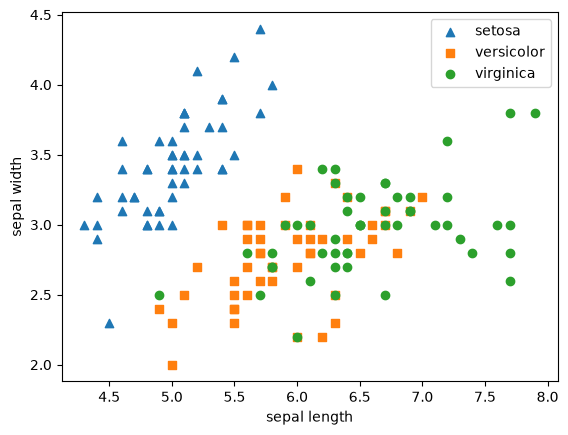

In [2]:
# setosa는 세모, versicolor는 네모, virginica는 동그라미로 표현
markers = ['^', 's', 'o']

# setosa의 target 값은 0, versicolor는 1, virginica는 2
# 각 target별로 다른 모양으로 산점도에 표시
for i, marker in enumerate(markers):
    x_axis_data = irisDF[irisDF['target'] == i]['sepal_length']
    y_axis_data = irisDF[irisDF['target'] == i]['sepal_width']
    plt.scatter(x_axis_data, y_axis_data, marker=marker, label=iris.target_names[i])

plt.legend()
plt.xlabel('sepal length')
plt.ylabel('sepal width')
plt.show()

- 여러 속성을 pca로 압축하기 전에 각 속성값을 동일한 스케일로 변환하는 것이 중요(스케일링)
- StandardScaler

In [3]:
from sklearn.preprocessing import StandardScaler

# target 열을 제외한 모든 특성을 평균 0, 표준편차 1로 표준화
iris_scaled = StandardScaler().fit_transform(irisDF.iloc[:, :-1])

- pca 적용, 4->2차원
- PCA 클래스, 생성 파라미터는 n_components (변환할 차원의 수를 의미)
- fit, transform
- 150x2 넘파이 행렬 가지게 됨

In [4]:
from sklearn.decomposition import PCA

pca = PCA(n_components=2)

# fit()과 transform()을 호출해 PCA 변환 데이터 반환
pca.fit(iris_scaled)
iris_pca = pca.transform(iris_scaled)
print(iris_pca.shape)

(150, 2)


In [5]:
# PCA 변환 데이터의 컬럼명을 각각 pca_component_1, pca_component_2로 지정
pca_columns = ['pca_component_1', 'pca_component_2']
irisDF_pca = pd.DataFrame(iris_pca, columns=pca_columns)
irisDF_pca['target'] = iris.target
irisDF_pca.head(3)

,pca_component_1,pca_component_2,target
0,-2.264703,0.480027,0
1,-2.080961,-0.674134,0
2,-2.364229,-0.341908,0


- 다시 2차원 상에서 분포 확인
- component1을 기반으로 세가지 품종 모두 어느정도 비교적 구분 잘 됨 -> component1이 원본 데이터의 변동성을 잘 반영했기 때문 

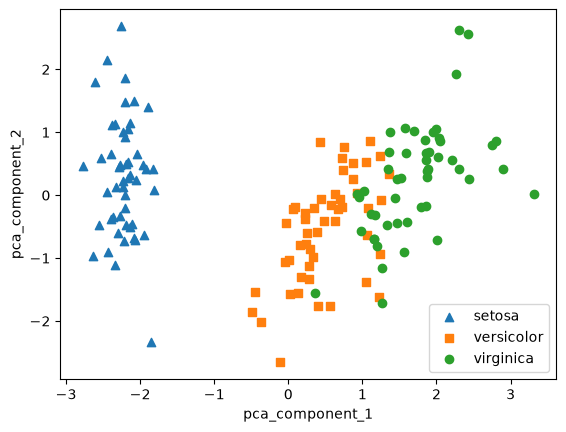

In [6]:
# setosa는 세모, versicolor는 네모, virginica는 동그라미로 표시
markers = ['^', 's', 'o']

# pca_component_1을 x축, pca_component_2를 y축으로 산점도 그리기
for i, marker in enumerate(markers):
    x_axis_data = irisDF_pca[irisDF_pca['target'] == i]['pca_component_1']
    y_axis_data = irisDF_pca[irisDF_pca['target'] == i]['pca_component_2']
    plt.scatter(x_axis_data, y_axis_data, marker=marker, label=iris.target_names[i])

plt.legend()
plt.xlabel('pca_component_1')
plt.ylabel('pca_component_2')
plt.show()

- PCA Component별로 원본 데이터의 변동성을 얼마나 반영하고 
있는지 확인
- pca의 explained_variance_ratio_ 속성: 전체 변동성에서 개별 pca 컴포넌트별로 차지하는 변동성 비율 제공
- pca_component_l이 전체 변동성의 약 72.9%를 차지하며, 두 번째인 
pca_component_2가 약 22.8%. 따라서 PCA를 2개 요소로만 변환해도 원본 데이터의 변동성을 95% 설명

In [7]:
print(pca.explained_variance_ratio_)

[0.72962445 0.22850762]


- 원본 붓꽃 데이터에 랜덤 포레스트 적용

In [8]:
from sklearn.ensemble import RandomForestClassifier
from sklearn.model_selection import cross_val_score
import numpy as np

rcf = RandomForestClassifier(random_state=156)
scores = cross_val_score(rcf, iris.data, iris.target, scoring='accuracy', cv=3)

print('원본 데이터 교차 검증 개별 정확도:', scores)
print('원본 데이터 평균 정확도:', np.mean(scores))

원본 데이터 교차 검증 개별 정확도: [0.98 0.94 0.96]
원본 데이터 평균 정확도: 0.96


- pca 변환 데이터에 랜덤 포레스트 적용
- 예측 정확도는 변환 차원 개수에 따라 성능이 떨어질 수밖에 없음 

In [9]:
pca_X = irisDF_pca[['pca_component_1', 'pca_component_2']]
scores_pca = cross_val_score(rcf, pca_X, iris.target, scoring='accuracy', cv=3)

print('PCA 변환 데이터 교차 검증 개별 정확도:', scores_pca)
print('PCA 변환 데이터 평균 정확도:', np.mean(scores_pca))

PCA 변환 데이터 교차 검증 개별 정확도: [0.88 0.88 0.88]
PCA 변환 데이터 평균 정확도: 0.88


## UCI Machine Learning Repository에 있는 신용카드 고객 데이터 세트 - pca 변환 

In [15]:
!pip install xlrd

데이터 확인
- 30000개 레코드, 24개 속성
- ‘default payment next month’ 속성이 Target 값 : 다음달 연체 여부, 연체(1)/정상납부(0)
- PAY_0 칼럼을 PAY_1 으로 칼럼명을 변환
- ‘default payment next month’ 칼럼이 너무 길어서 ‘default’로 변경
- Target 속성인 ‘default’ 칼럼을 y_target 변수로 별도로 저장하고 피처 데이터는 이 default 칼럼을 제외한 별도의 DataFrame으로 만들기

In [16]:
# header=1로 둘째 행을 열 이름으로 사용하고, iloc으로 첫 번째 ID 열 제거
import pandas as pd

df = pd.read_excel(r"C:\Users\user\ESAA_YB\pca_credit_card.xls", header=1, sheet_name='Data').iloc[0:, 1:]
print(df.shape)
df.head(3)

(30000, 24)


,LIMIT_BAL,SEX,EDUCATION,MARRIAGE,AGE,PAY_0,PAY_2,PAY_3,PAY_4,PAY_5,...,BILL_AMT4,BILL_AMT5,BILL_AMT6,PAY_AMT1,PAY_AMT2,PAY_AMT3,PAY_AMT4,PAY_AMT5,PAY_AMT6,default payment next month
0,20000,2,2,1,24,2,2,-1,-1,-2,...,0,0,0,0,689,0,0,0,0,1
1,120000,2,2,2,26,-1,2,0,0,0,...,3272,3455,3261,0,1000,1000,1000,0,2000,1
2,90000,2,2,2,34,0,0,0,0,0,...,14331,14948,15549,1518,1500,1000,1000,1000,5000,0


In [17]:
df.rename(columns={'PAY_0': 'PAY_1', 'default payment next month': 'default'}, inplace=True)
y_target = df['default']
X_features = df.drop('default', axis=1)

- 타겟변수 제외 23개 속성이 있고 속성끼리 상관도 매우 높음
- DataFrame의 corr()를 이용해 각 속성 간의 상관도를 구한 뒤 이를 시본(Seaborn) 의 heatmap으로 시각화
- BILL_AMT1 〜 BILL_AMT6 6개 속성끼리의 상관도가 대부분 0.9 이상으로 매우 높음
- PAY_1 〜 PAY_6까지의 속성 역시 상관도가 높음
- 이렇게 높은 상관도를 가진 속성들은 소수의 PCA만으로 자연스럽게 이 속성들의 변동성을 수용할 수 있음 


<Axes: >

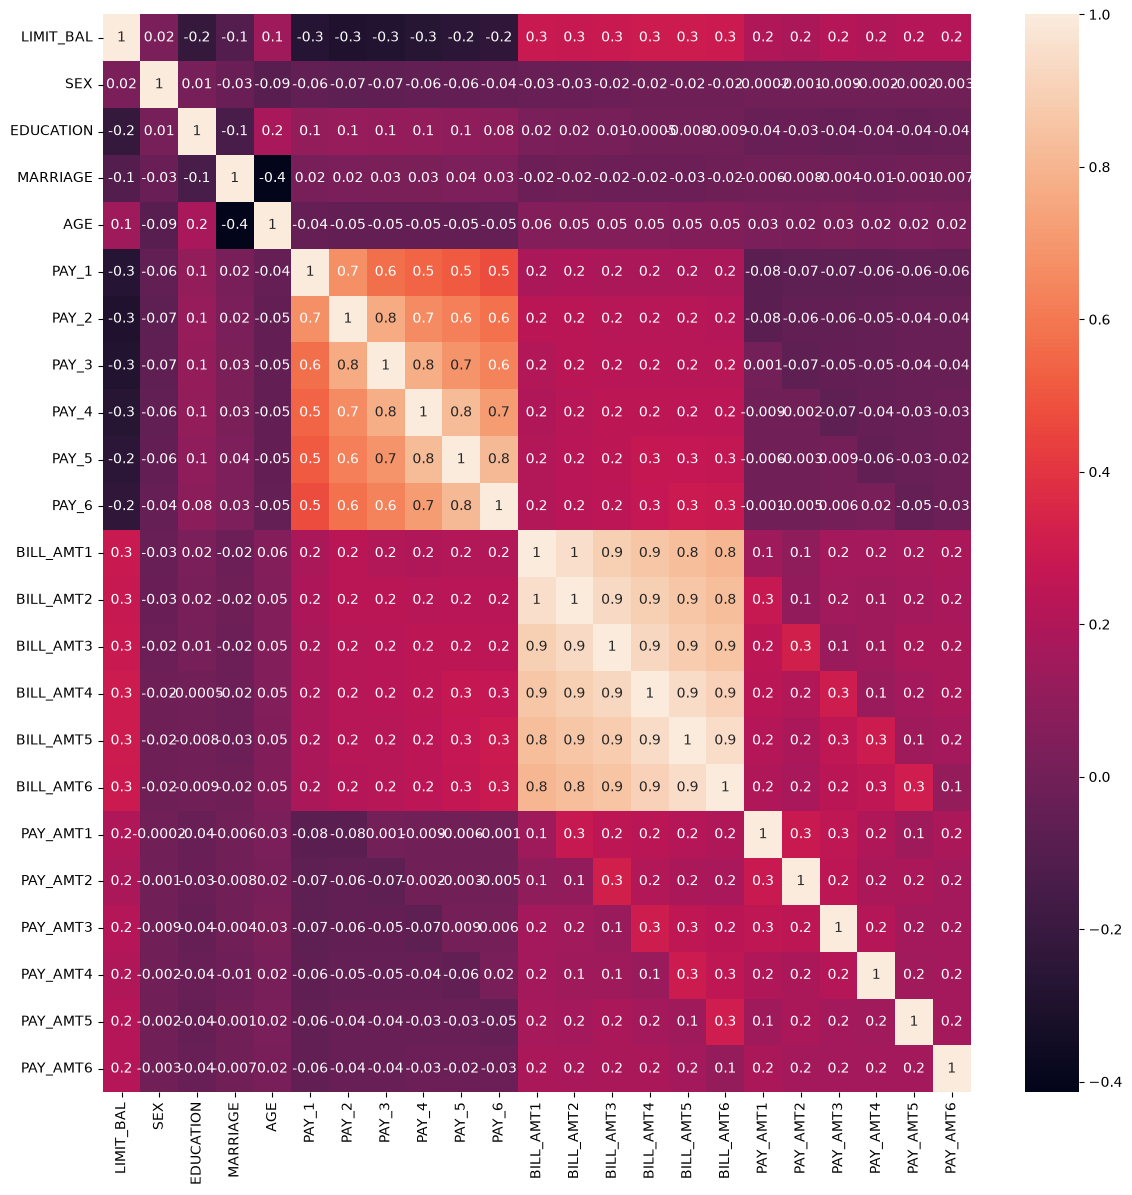

In [18]:
import seaborn as sns
import matplotlib.pyplot as plt

%matplotlib inline

corr = X_features.corr()
plt.figure(figsize=(14, 14))
sns.heatmap(corr, annot=True, fmt='.1g')

- BILL_ AMT1 〜 BILL_AMT6까지 6개 속성을 2개의 컴포넌트로 PCA 변환
- 개별 컴포넌트의 변동성을 explained_variance_ratio_ 속성으로 확인
- 단 2개 컴포넌트만으로 6개 속성의 변동성을 약 95%이상 설명함 

In [19]:
from sklearn.decomposition import PCA
from sklearn.preprocessing import StandardScaler

# BILL_AMT1부터 BILL_AMT6까지 6개 열 이름 생성
cols_bill = ['BILL_AMT' + str(i) for i in range(1, 7)]
print('대상 속성명:', cols_bill)

# 청구 금액을 표준화한 뒤 PCA를 학습하고, 두 주성분의 설명 분산 비율 출력
scaler = StandardScaler()
df_cols_scaled = scaler.fit_transform(X_features[cols_bill])

pca = PCA(n_components=2)
pca.fit(df_cols_scaled)
print('PCA Component별 변동성:', pca.explained_variance_ratio_)

대상 속성명: ['BILL_AMT1', 'BILL_AMT2', 'BILL_AMT3', 'BILL_AMT4', 'BILL_AMT5', 'BILL_AMT6']
PCA Component별 변동성: [0.90555253 0.0509867 ]


원본 데이터 세트와 6개의 컴포넌트로 PCA 변환한 데이터 세트의 분류 예측 결과를 상호 비교  
- 원본 데이터 세트에 랜덤 포레스트를 이용해 타깃 값이 디폴트 값을 3개의 교차 검증 세트로 분류 예측
-  평균 예측 정확도는 약 81.70%

In [20]:
import numpy as np
from sklearn.ensemble import RandomForestClassifier
from sklearn.model_selection import cross_val_score

rcf = RandomForestClassifier(n_estimators=300, random_state=156)
scores = cross_val_score(rcf, X_features, y_target, scoring='accuracy', cv=3)

print('CV=3 인 경우의 개별 Fold세트별 정확도:', scores)
print('평균 정확도:{0:.4f}'.format(np.mean(scores)))

CV=3 인 경우의 개별 Fold세트별 정확도: [0.8083 0.8196 0.8232]
평균 정확도:0.8170


-  6개의 컴포넌트로 PCA 변환한 데이터 세트에 대해서 동일하게 분류 예측을 적용
-  예측 성능이 저하되었지만 단 1~2%임, 전체 23개 속성의 1/4인 6개만으로도 이 정도 예측 성능을 유지하는 게 pca 압축 능력이 뛰어나다는 거임 

In [21]:

from sklearn.decomposition import PCA
from sklearn.preprocessing import StandardScaler

# 원본 데이터 세트에 먼저 StandardScaler 적용
scaler = StandardScaler()
df_scaled = scaler.fit_transform(X_features)

# 6개의 주성분으로 PCA 변환을 수행하고 교차 검증 정확도 계산
pca = PCA(n_components=6)
df_pca = pca.fit_transform(df_scaled)
scores_pca = cross_val_score(rcf, df_pca, y_target, scoring='accuracy', cv=3)

print('CV=3 인 경우의 PCA 변환된 개별 Fold 세트별 정확도:', scores_pca)
print('PCA 변환 데이터 세트 평균 정확도:{0:.4f}'.format(np.mean(scores_pca)))

CV=3 인 경우의 PCA 변환된 개별 Fold 세트별 정확도: [0.7913 0.7972 0.802 ]
PCA 변환 데이터 세트 평균 정확도:0.7968


# **03 LDA(Linear Discriminant Analysis)**

- LDA : 선형 판별 분석법, 입력 데이터 세트를 저차원 공간에 투영해 차원을 축소하지만(pca처럼), 지도학습의 분류에서 사용하기 쉽도록 개별 클래스를 분별할 수 있는 기준을 최대한 유지하면서 축소

- PCA는 입력 데이터의 변동성의 가장 큰 축을 찾았지만, LDA는 입력 데이터의 결정 값 클래스를 최대한으로 분리할 수 있는 축을 찾음

- 특정 공간상에서 클래스 분리를 최대화하는 축을 찾기 위해 클래스 간 분산(between-class scatter)과 클래스 내부 분산(within-class scatter)의 비율을 최대화하는 방식으로

- 클래스 간 분산은 최대한 크게, 클래스 내부 분산은 최대한 작게

- 클래스 간 분산과 내부 분산 행렬을 생성하고 고유벡터 구하기

## 붓꽃 데이터 세트에 LDA 적용
- 붓꽃 데이터 세트를 사이킷런의 LDA를 이용해 변환하고, 그 결과를 품종별로 시각화
- 사이킷런은 LDA를 LinearDiscriminantAnalysis 클래스로 제공
- 먼저 붓꽃 데이터 세트 로드, 표준 정규 분포로 스케일링 

In [22]:
from sklearn.discriminant_analysis import LinearDiscriminantAnalysis
from sklearn.preprocessing import StandardScaler
from sklearn.datasets import load_iris

iris = load_iris()
iris_scaled = StandardScaler().fit_transform(iris.data)

- 2개의 컴포넌트로 데이터를 LDA 변환하기
- LDA는 지도학습이라서 클래스의 결정 값이 변환 시에 필요함
- fit 메서드를 호출할 때 이를 적용 

In [23]:
lda = LinearDiscriminantAnalysis(n_components=2)
lda.fit(iris_scaled, iris.target)
iris_lda = lda.transform(iris_scaled)
print(iris_lda.shape)

(150, 2)


- LDA 변환된 입력 데이터 값을 2차원 평면에 품종별로 표현해보기
- PCA로 변환된 데이터와 좌우 대칭 형태로 많이 닮아 있음을 알 수 있음

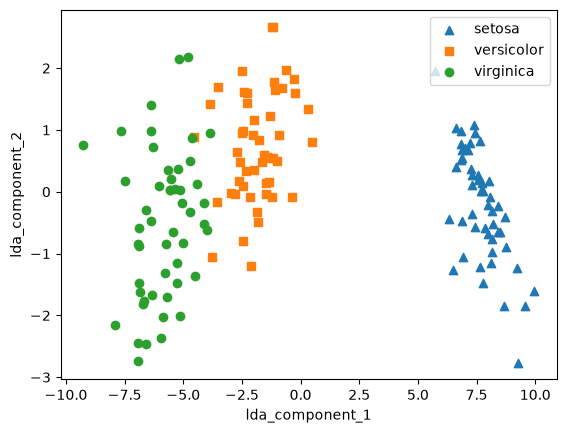

In [24]:
import pandas as pd
import matplotlib.pyplot as plt

%matplotlib inline

lda_columns = ['lda_component_1', 'lda_component_2']
irisDF_lda = pd.DataFrame(iris_lda, columns=lda_columns)
irisDF_lda['target'] = iris.target

# setosa는 세모, versicolor는 네모, virginica는 동그라미로 표현
markers = ['^', 's', 'o']

# setosa의 target 값은 0, versicolor는 1, virginica는 2
# 각 target을 다른 모양으로 산점도에 표시
for i, marker in enumerate(markers):
    x_axis_data = irisDF_lda[irisDF_lda['target'] == i]['lda_component_1']
    y_axis_data = irisDF_lda[irisDF_lda['target'] == i]['lda_component_2']
    plt.scatter(x_axis_data, y_axis_data, marker=marker, label=iris.target_names[i])

plt.legend(loc='upper right')
plt.xlabel('lda_component_1')
plt.ylabel('lda_component_2')
plt.show()

# **04 SVD(Singular Value Decomposition)**

- SVD : PCA와 유사한 행렬 분해 기법 이용, 특이값 분해
- A 차원이 m X n일 때 = U의 차원이 m X m, 대각행렬의 차원이 m X n, V_t의 차원이 n X n으로 분해
- A 차원이 m X n일 때 = U의 차원이 m X p, 대각행렬의 차원이 p X p, V_t의 차원이 p X n으로 분해
- Truncated SVD : 대각행렬의 대각원소 중에 상위 몇 개만 추출해서 여기에 대응하는 U와 V의 원소도 함께 제거해 더욱 차원을 줄인 형태로 분해

- 넘파이의 SVD 모듈인 numpy.linalg.svd를 로딩
- 랜덤한 4x4 넘파이 행렬 생성 

In [25]:
# 넘파이의 svd 모듈 임포트
import numpy as np
from numpy.linalg import svd

# 4×4 랜덤 행렬 a 생성
np.random.seed(121)
a = np.random.randn(4, 4)
print(np.round(a, 3))

[[-0.212 -0.285 -0.574 -0.44 ]
 [-0.33   1.184  1.615  0.367]
 [-0.014  0.63   1.71  -1.327]
 [ 0.402 -0.191  1.404 -1.969]]


- a 행렬에 svd를 적용하여 U, Sigma, Vt 도출하기

In [26]:
U, Sigma, Vt = svd(a)
print(U.shape, Sigma.shape, Vt.shape)
print('U matrix:\n', np.round(U, 3))
print('Sigma Value:\n', np.round(Sigma, 3))
print('V transpose matrix:\n', np.round(Vt, 3))

(4, 4) (4,) (4, 4)
U matrix:
 [[-0.079 -0.318  0.867  0.376]
 [ 0.383  0.787  0.12   0.469]
 [ 0.656  0.022  0.357 -0.664]
 [ 0.645 -0.529 -0.328  0.444]]
Sigma Value:
 [3.423 2.023 0.463 0.079]
V transpose matrix:
 [[ 0.041  0.224  0.786 -0.574]
 [-0.2    0.562  0.37   0.712]
 [-0.778  0.395 -0.333 -0.357]
 [-0.593 -0.692  0.366  0.189]]


- 이렇게 분해된 행렬들을 이용해 다시 원본 행렬로 정확히 복원되는지 확인
- 이 3개 행렬을 내적하면 됨 sigma의 경우 0이 아닌 값만 1차원으로 추출했으므로 다시 0을 포함한 대칭행렬로 변환한 뒤에 내적 수행해야 함 

In [28]:
# Sigma를 다시 0을 포함한 대각행렬로 변환
Sigma_mat = np.diag(Sigma)
#내적 수행 
a_ = np.dot(np.dot(U, Sigma_mat), Vt)
print(np.round(a_, 3))
     

[[-0.212 -0.285 -0.574 -0.44 ]
 [-0.33   1.184  1.615  0.367]
 [-0.014  0.63   1.71  -1.327]
 [ 0.402 -0.191  1.404 -1.969]]


- 데이터 세트가 로우 간 의존성이 있을 경우 어떻게 sigma 값이 변하고, 이에 따른 차원 축소가 진행될 수 있는지 확인
- 일부러 의존성 부여 -> a 행렬의 로우를 업데이트 

In [29]:
a[2] = a[0] + a[1]
a[3] = a[0]
print(np.round(a, 3))

[[-0.212 -0.285 -0.574 -0.44 ]
 [-0.33   1.184  1.615  0.367]
 [-0.542  0.899  1.041 -0.073]
 [-0.212 -0.285 -0.574 -0.44 ]]


- 의존성이 높아진 상태에서 svd 분해해보기
- 차원은 같지만 sigma 값중 2개가 0으로 변함. 즉 선형 독립인 로우 벡터의 개수가 2개라는 뜻 (rank=2)

In [30]:
# 다시 SVD를 수행해 Sigma 값 확인
U, Sigma, Vt = svd(a)
print(U.shape, Sigma.shape, Vt.shape)
print('Sigma Value:\n', np.round(Sigma, 3))

(4, 4) (4,) (4, 4)
Sigma Value:
 [2.663 0.807 0.    0.   ]


- 이 3개 행렬로 다시 원본 행렬로 복원
- 전체 데이터가 아니라 sigma 0에 대응하는 데이터를 제외하고 복원

In [31]:

# U 행렬에서 처음 두 특잇값에 대응하는 열을 추출
U_ = U[:, :2]
Sigma_ = np.diag(Sigma[:2])

# V의 전치 행렬에서 처음 두 행을 추출
Vt_ = Vt[:2]
print(U_.shape, Sigma_.shape, Vt_.shape)

# 세 행렬을 곱해 원본 행렬을 복원
a_ = np.dot(np.dot(U_, Sigma_), Vt_)
print(np.round(a_, 3))

(4, 2) (2, 2) (2, 4)
[[-0.212 -0.285 -0.574 -0.44 ]
 [-0.33   1.184  1.615  0.367]
 [-0.542  0.899  1.041 -0.073]
 [-0.212 -0.285 -0.574 -0.44 ]]


- Truncated SVD를 이용해 행렬 분해해보기
-  Truncated SVD :  대각 행렬에 있는 대각원소, 즉 특이값 중 상위 일부 데이터만 추출해 분해하는 방식. 이렇게 분해하면 인위적으로 더 작은 차원으로 분해하기 때문에 원본 행렬을 정확하게 다시 원복할 수는 없음, 하지만 상당 수준 근사
- 사이파이 모듈 사용, 희소행렬로만 지원돼서scipy.sparse.linalg.svds 이용
- 랜덤 6x6 행렬을 normal svd로 분해 후 다시 truncated svd로 분해, 그 후 내적을 계산하여 다시 복원해보기 

In [32]:
import numpy as np
from scipy.sparse.linalg import svds
from scipy.linalg import svd

# 원본 행렬을 출력하고 SVD 적용 후 U, Sigma, Vt의 차원 확인
np.random.seed(121)
matrix = np.random.random((6, 6))
print('원본 행렬:\n', matrix)

U, Sigma, Vt = svd(matrix, full_matrices=False)
print('\n분해 행렬 차원:', U.shape, Sigma.shape, Vt.shape)
print('\nSigma값 행렬:', Sigma)

# 특잇값 4개를 사용해 Truncated SVD 수행
num_components = 4
U_tr, Sigma_tr, Vt_tr = svds(matrix, k=num_components)
print('\nTruncated SVD 분해 행렬 차원:', U_tr.shape, Sigma_tr.shape, Vt_tr.shape)
print('\nTruncated SVD Sigma값 행렬:', Sigma_tr)

matrix_tr = np.dot(np.dot(U_tr, np.diag(Sigma_tr)), Vt_tr)
print('\nTruncated SVD로 분해 후 복원 행렬:\n', matrix_tr)

원본 행렬:
 [[0.11133083 0.21076757 0.23296249 0.15194456 0.83017814 0.40791941]
 [0.5557906  0.74552394 0.24849976 0.9686594  0.95268418 0.48984885]
 [0.01829731 0.85760612 0.40493829 0.62247394 0.29537149 0.92958852]
 [0.4056155  0.56730065 0.24575605 0.22573721 0.03827786 0.58098021]
 [0.82925331 0.77326256 0.94693849 0.73632338 0.67328275 0.74517176]
 [0.51161442 0.46920965 0.6439515  0.82081228 0.14548493 0.01806415]]

분해 행렬 차원: (6, 6) (6,) (6, 6)

Sigma값 행렬: [3.2535007  0.88116505 0.83865238 0.55463089 0.35834824 0.0349925 ]

Truncated SVD 분해 행렬 차원: (6, 4) (4,) (4, 6)

Truncated SVD Sigma값 행렬: [0.55463089 0.83865238 0.88116505 3.2535007 ]

Truncated SVD로 분해 후 복원 행렬:
 [[0.19222941 0.21792946 0.15951023 0.14084013 0.81641405 0.42533093]
 [0.44874275 0.72204422 0.34594106 0.99148577 0.96866325 0.4754868 ]
 [0.12656662 0.88860729 0.30625735 0.59517439 0.28036734 0.93961948]
 [0.23989012 0.51026588 0.39697353 0.27308905 0.05971563 0.57156395]
 [0.83806144 0.78847467 0.93868685 0.72673231 

## 사이킷런 TruncatedSVD 클래스를 이용한 변환

- 사이킷런의 TruncatedSVD 클래스: 사이파이의 svds와 같이 Truncated SVD 연산을 수행해 원본 행렬을 분해한 U, Sigma, Vt 행렬을 반환하지는 않음.
- PCA 클래스와 유사하게 fit()와 transform()을 호출해 원본 데이터를 몇 개의 주요 컴포넌트(즉, Truncated SVD의 K 컴포넌트 수)로 차원을 축소해 변환
- 원본 데이터를 Truncated SVD 방식으로 분해된 U*Sigma 행렬에 선형 변환해 생성.
- 붓꽃 데이터 세트를 TruncatedSVD를 이용해 변환해보기

Text(0, 0.5, 'TruncatedSVD Component 2')

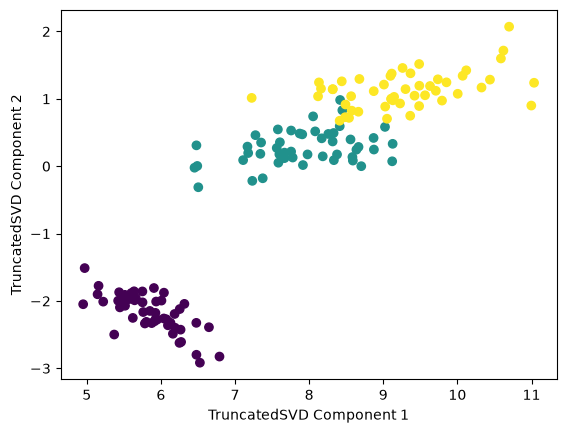

In [33]:
from sklearn.decomposition import TruncatedSVD, PCA
from sklearn.datasets import load_iris
import matplotlib.pyplot as plt

%matplotlib inline

iris = load_iris()
iris_ftrs = iris.data

# 2개의 컴포넌트로 TruncatedSVD 변환
tsvd = TruncatedSVD(n_components=2)
tsvd.fit(iris_ftrs)
iris_tsvd = tsvd.transform(iris_ftrs)

# 변환된 데이터를 2차원 산점도로 표시하고 품종은 색깔로 구분
plt.scatter(x=iris_tsvd[:, 0], y=iris_tsvd[:, 1], c=iris.target)
plt.xlabel('TruncatedSVD Component 1')
plt.ylabel('TruncatedSVD Component 2')

Text(0.5, 1.0, 'PCA Transformed')

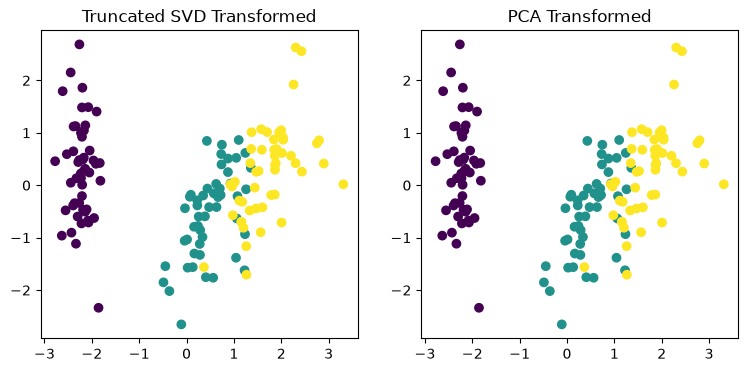

In [34]:
from sklearn.preprocessing import StandardScaler

# 붓꽃 데이터를 StandardScaler로 변환
scaler = StandardScaler()
iris_scaled = scaler.fit_transform(iris_ftrs)

# 표준화된 데이터에 TruncatedSVD 적용
tsvd = TruncatedSVD(n_components=2)
tsvd.fit(iris_scaled)
iris_tsvd = tsvd.transform(iris_scaled)

# 표준화된 데이터에 PCA 적용
pca = PCA(n_components=2)
pca.fit(iris_scaled)
iris_pca = pca.transform(iris_scaled)

# 왼쪽에 TruncatedSVD 결과, 오른쪽에 PCA 결과 표시
fig, (ax1, ax2) = plt.subplots(figsize=(9, 4), ncols=2)
ax1.scatter(x=iris_tsvd[:, 0], y=iris_tsvd[:, 1], c=iris.target)
ax2.scatter(x=iris_pca[:, 0], y=iris_pca[:, 1], c=iris.target)
ax1.set_title('Truncated SVD Transformed')
ax2.set_title('PCA Transformed')

- 사이킷런의 TruncatedSVD와 PCA 클래스 구현을 조금 더 자세히 들여다보면 두 개 클래스 모두 SVD 를 이용해 행렬을 분해.
- 붓꽃 데이터를 스케일링으로 변환한 뒤에 TruncatedSVD와 PCA 클래 
스 변환을 해보면 두 개가 거의 동일함
- 두 개의 변환 행렬 값과 원복 속성별 컴포넌트 비율값을 실제로 서로 비교해 보면 거의 같음
- 데이터 세트가 스케일링으로 데이터 중심이 동일해지면 사이킷런의 SVD와 PCA는 동일한 변환을 수행. 이는 PCA가 SVD 알고리즘으로 구현됐음을 의미. 하지만 PCA는 밀집 행렬(Dense Matrix)에 대한 변환만 
가능하며 SVD는 희소 행렬(Sparse Matrix)에 대한 변환도 가능

In [35]:
print((iris_pca - iris_tsvd).mean())
print((pca.components_ - tsvd.components_).mean())

2.333972135929822e-15
-2.8189256484623115e-17


# **05 NMF(Non-Negative Matrix Factorization)**

- NMF : truncated svd와 같이 낮은 랭크를 통한 행렬 근사 방식의 변형
- 원본 행렬 내의 모든 원소 값이 모두 양수(0 이상)라는 게 보장되면 다음과 같이(책에 그림) 좀 더 간단하게 두 개의 기반 양수 행렬로 분해될 수 있는 기법을 지칭
- 4 X 6 원본 행렬 V = 4 X 2 행렬 W와 2 X 6 행렬 H로 근사해 분해

C:\Users\user\anaconda3\Lib\site-packages\sklearn\decomposition\_nmf.py:1723: ConvergenceWarning: Maximum number of iterations 200 reached. Increase it to improve convergence.
  warnings.warn(


Text(0, 0.5, 'NMF Component 2')

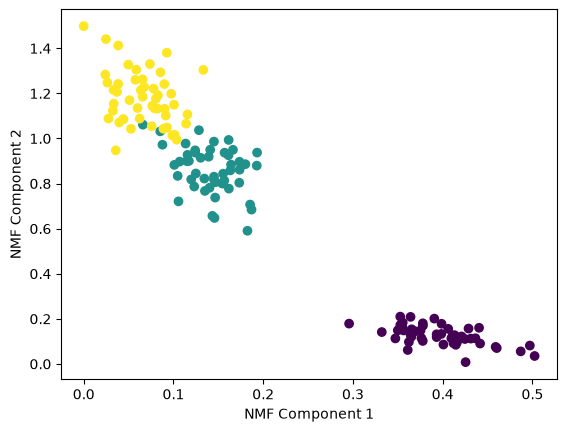

In [36]:

from sklearn.decomposition import NMF
from sklearn.datasets import load_iris
import matplotlib.pyplot as plt

%matplotlib inline

iris = load_iris()
iris_ftrs = iris.data

nmf = NMF(n_components=2)
nmf.fit(iris_ftrs)
iris_nmf = nmf.transform(iris_ftrs)

plt.scatter(x=iris_nmf[:, 0], y=iris_nmf[:, 1], c=iris.target)
plt.xlabel('NMF Component 1')
plt.ylabel('NMF Component 2')

- SVD와 NMF는 매우 많은 피처 데이터를 가진 고차원 행렬을 두 개의 저차원 행렬로 분리하는 행렬 분해 기법. 특히 이러한 행렬 분해를 수행하면서 원본 행렬에서 잠재된 요소를 추출하기 때문에 토픽 모델링이나 추천 시스템에서 활발하게 사용.